In [ ]:
!ls


sample_data


In [ ]:
import pandas as pd
import numpy as np


In [ ]:
# Sklearn modules for classification
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
print("Libraries loaded")

Libraries loaded


In [ ]:
# Step 1: Load the data
df = pd.read_csv("dataset-1.csv", header=None)

In [ ]:
df.head()


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1,4950-BDEUX,Male,0,No,No,35,No,No phone service,DSL,No,...,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.2,1701.65,False
2,7993-NQLJE,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,75.1,1151.55,False
3,7321-ZNSLA,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,...,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,False
4,4922-CVPDX,Female,0,Yes,No,26,Yes,No,DSL,No,...,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.5,1905.7,False


In [ ]:
print("Rows, columns:", df.shape)
print("Data types summary:")
print(df.dtypes.value_counts())

Rows, columns: (5635, 21)
Data types summary:
object    21
Name: count, dtype: int64


In [ ]:
# Step 2: Explore the data
print("Missing values in dataset:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in dataset: 0
Duplicate rows: 0


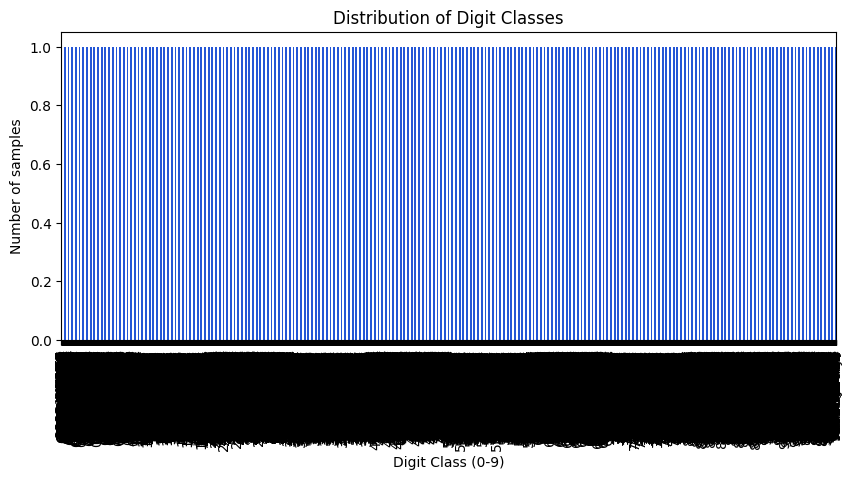

In [ ]:
plt.figure(figsize=(10, 4))
df[0].value_counts().sort_index().plot(kind='bar', color='#2456D6')
plt.xlabel("Digit Class (0-9)")
plt.ylabel("Number of samples")
plt.title("Distribution of Digit Classes")
plt.show()

In [ ]:
# Step 3: Separate features (X) and label (y)
X = df.drop(columns=['customerID', 'Churn'], errors='ignore')
y = df['Churn'].astype(int)

KeyError: 'Churn'

In [25]:
# Step 4: Split into training and test sets

X_train_raw, X_temp, y_train_raw, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train rows: {len(X_train_raw)}")
print(f"Validation rows: {len(X_val_raw)}")
print(f"Test rows: {len(X_test_raw)}")

ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [ ]:
# Step 5: Scale the features (pre-processing)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ValueError: could not convert string to float: 'Male'